## 2.1 Model Selection

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import f1_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier

from decision_tree import DecisionTree

seed = 42

In [19]:
data = np.genfromtxt("churn-data.csv", delimiter=",", dtype=float, names=True)
feature_names = list(data.dtype.names[:-1])
target_name = data.dtype.names[-1]

X = np.array([data[feature] for feature in feature_names]).T
y = data[target_name].astype(int)

print(f"Feature columns names: {feature_names}")
print(f"Target column name: {target_name}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Feature columns names: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Target column name: Churn
X shape: (7032, 19)
y shape: (7032,)


In [20]:
# check class distribution
classes, counts = np.unique(y, return_counts=True)

print("Classes:", classes)
print("Counts:", counts)

Classes: [0 1]
Counts: [5163 1869]


In [21]:
# split data into 80% training and 20% test data 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=seed
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (5625, 19)
Test set: (1407, 19)


In [22]:
# hyperparameters
criteria = ["entropy", "gini"]
max_depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, None]

# 5-fold cross-validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

In [24]:
# store the results for each hyperparameter combination
results = []

for criterion in criteria:
    for max_depth in max_depths:

        fold_scores = []

        # run 5-fold cross-validation
        for train_index, val_index in kf.split(X_train):

            X_fold_train = X_train[train_index]
            y_fold_train = y_train[train_index]

            X_fold_val = X_train[val_index]
            y_fold_val = y_train[val_index]

            # create and train the decision tree
            tree = DecisionTree(
                criterion=criterion,
                max_depth=max_depth
            )

            tree.fit(X_fold_train, y_fold_train)

            # predict on the validation fold and calculate F1-score
            y_pred = tree.predict(X_fold_val)

            score = f1_score(y_fold_val, y_pred)
            fold_scores.append(score)

        # mean F1-score across the five folds
        mean_f1 = np.mean(fold_scores)

        results.append((criterion, max_depth, mean_f1))

        print(
            f"Criterion: {criterion}, "
            f"Max depth: {max_depth}, "
            f"Mean F1: {mean_f1:.4f}"
        )

Criterion: entropy, Max depth: 1, Mean F1: 0.0000
Criterion: entropy, Max depth: 2, Mean F1: 0.6019
Criterion: entropy, Max depth: 3, Mean F1: 0.5195
Criterion: entropy, Max depth: 4, Mean F1: 0.5505
Criterion: entropy, Max depth: 5, Mean F1: 0.5566
Criterion: entropy, Max depth: 6, Mean F1: 0.5552
Criterion: entropy, Max depth: 7, Mean F1: 0.5785
Criterion: entropy, Max depth: 8, Mean F1: 0.5727
Criterion: entropy, Max depth: 9, Mean F1: 0.5546
Criterion: entropy, Max depth: 10, Mean F1: 0.5175
Criterion: entropy, Max depth: None, Mean F1: 0.5018
Criterion: gini, Max depth: 1, Mean F1: 0.0000
Criterion: gini, Max depth: 2, Mean F1: 0.6019
Criterion: gini, Max depth: 3, Mean F1: 0.5195
Criterion: gini, Max depth: 4, Mean F1: 0.5658
Criterion: gini, Max depth: 5, Mean F1: 0.5569
Criterion: gini, Max depth: 6, Mean F1: 0.5660
Criterion: gini, Max depth: 7, Mean F1: 0.5812
Criterion: gini, Max depth: 8, Mean F1: 0.5798
Criterion: gini, Max depth: 9, Mean F1: 0.5574
Criterion: gini, Max de

In [25]:
# select hyperparameter combination with highest mean F1-score
best_result = max(results, key=lambda x: x[2])

best_criterion = best_result[0]
best_max_depth = best_result[1]
best_f1 = best_result[2]

print("Best criterion:", best_criterion)
print("Best max depth:", best_max_depth)
print(f"Best mean F1: {best_f1:.4f}")

Best criterion: entropy
Best max depth: 2
Best mean F1: 0.6019


## 2.2 Model Evaluation and Comparison

We first repeat the same model selection procedure for sklearn's decision tree. Then the selected models are trained on the full training set and evaluated on the test set. The same model selection procedure is repeated for sklearn's DecisionTreeClassifier for a fair comparison.

In [27]:
# store the results for each hyperparameter combination
sklearn_results = []

for criterion in criteria:
    for max_depth in max_depths:

        fold_scores = []

        # run 5-fold cross-validation
        for train_index, val_index in kf.split(X_train):

            X_fold_train = X_train[train_index]
            y_fold_train = y_train[train_index]

            X_fold_val = X_train[val_index]
            y_fold_val = y_train[val_index]

            # create and train the decision tree
            tree = DecisionTreeClassifier(
                criterion=criterion,
                max_depth=max_depth,
                random_state=seed
            )

            tree.fit(X_fold_train, y_fold_train)

            # predict on the validation fold and calculate F1-score
            y_pred = tree.predict(X_fold_val)

            score = f1_score(y_fold_val, y_pred)
            fold_scores.append(score)

        # mean F1-score across the five folds
        mean_f1 = np.mean(fold_scores)

        sklearn_results.append((criterion, max_depth, mean_f1))

        print(
            f"Criterion: {criterion}, "
            f"Max depth: {max_depth}, "
            f"Mean F1: {mean_f1:.4f}"
        )

Criterion: entropy, Max depth: 1, Mean F1: 0.0000
Criterion: entropy, Max depth: 2, Mean F1: 0.5921
Criterion: entropy, Max depth: 3, Mean F1: 0.4688
Criterion: entropy, Max depth: 4, Mean F1: 0.5739
Criterion: entropy, Max depth: 5, Mean F1: 0.5732
Criterion: entropy, Max depth: 6, Mean F1: 0.5709
Criterion: entropy, Max depth: 7, Mean F1: 0.5780
Criterion: entropy, Max depth: 8, Mean F1: 0.5598
Criterion: entropy, Max depth: 9, Mean F1: 0.5670
Criterion: entropy, Max depth: 10, Mean F1: 0.5452
Criterion: entropy, Max depth: None, Mean F1: 0.4935
Criterion: gini, Max depth: 1, Mean F1: 0.0000
Criterion: gini, Max depth: 2, Mean F1: 0.5921
Criterion: gini, Max depth: 3, Mean F1: 0.4738
Criterion: gini, Max depth: 4, Mean F1: 0.5569
Criterion: gini, Max depth: 5, Mean F1: 0.5867
Criterion: gini, Max depth: 6, Mean F1: 0.5727
Criterion: gini, Max depth: 7, Mean F1: 0.5666
Criterion: gini, Max depth: 8, Mean F1: 0.5615
Criterion: gini, Max depth: 9, Mean F1: 0.5448
Criterion: gini, Max de

In [28]:
# select hyperparameter combination with highest mean F1-score
best_sklearn_result = max(sklearn_results, key=lambda x: x[2])

best_sklearn_criterion = best_sklearn_result[0]
best_sklearn_max_depth = best_sklearn_result[1]
best_sklearn_f1 = best_sklearn_result[2]

print("Best sklearn criterion:", best_sklearn_criterion)
print("Best sklearn max depth:", best_sklearn_max_depth)
print(f"Best sklearn mean F1: {best_sklearn_f1:.4f}")

Best sklearn criterion: entropy
Best sklearn max depth: 2
Best sklearn mean F1: 0.5921


Train both selected models on the full training set and evaluate them on the test set using F1-score.

In [36]:
# train and evaluate our DecisionTree
best_tree = DecisionTree(
    criterion=best_criterion,
    max_depth=best_max_depth
)

best_tree.fit(X_train, y_train)

y_pred_own = best_tree.predict(X_test)

own_test_f1 = f1_score(y_test, y_pred_own)


# train and evaluate sklearn DecisionTreeClassifier
best_sklearn_tree = DecisionTreeClassifier(
    criterion=best_sklearn_criterion,
    max_depth=best_sklearn_max_depth,
    random_state=seed
)

best_sklearn_tree.fit(X_train, y_train)

y_pred_sklearn = best_sklearn_tree.predict(X_test)

sklearn_test_f1 = f1_score(y_test, y_pred_sklearn)


print(f"Own DecisionTree F1: {own_test_f1:.4f}")
print(f"sklearn DecisionTree F1: {sklearn_test_f1:.4f}")

Own DecisionTree F1: 0.5758
sklearn DecisionTree F1: 0.5758


## 3. Feature Importance

Calculate permutation importance to see which features have the most influence on the model's predictions.

In [30]:
# calculate permutation importance
def permutation_importance(model, X, y, metric, n_repeats, seed):
    rng = np.random.default_rng(seed)

    # calculate baseline score
    baseline_score = metric(y, model.predict(X))

    importances = []

    # calculate importance for each feature
    for feature in range(X.shape[1]):
        scores = []

        for _ in range(n_repeats):
            X_permuted = X.copy()

            # shuffle one feature
            X_permuted[:, feature] = rng.permutation(
                X_permuted[:, feature]
            )

            y_pred = model.predict(X_permuted)
            score = metric(y, y_pred)

            scores.append(score)
            
        # decrease in performance after shuffling   
        mean_permuted_score = np.mean(scores)
        importance = baseline_score - mean_permuted_score

        importances.append(importance)

    return np.array(importances)

In [31]:
# calculate permutation importance on the test set
importances = permutation_importance(
    best_tree,
    X_test,
    y_test,
    accuracy_score,
    n_repeats=30,
    seed=seed
)

In [35]:
for feature, importance in zip(feature_names, importances):
    print(f"{feature}: {importance:.4f}")

gender: 0.0000
SeniorCitizen: 0.0000
Partner: 0.0000
Dependents: 0.0000
tenure: 0.0000
PhoneService: 0.0000
MultipleLines: 0.0000
InternetService: 0.0000
OnlineSecurity: 0.0403
OnlineBackup: 0.0000
DeviceProtection: 0.0000
TechSupport: 0.0000
StreamingTV: 0.0000
StreamingMovies: 0.0000
Contract: 0.0475
PaperlessBilling: 0.0000
PaymentMethod: 0.0000
MonthlyCharges: 0.0000
TotalCharges: 0.0000


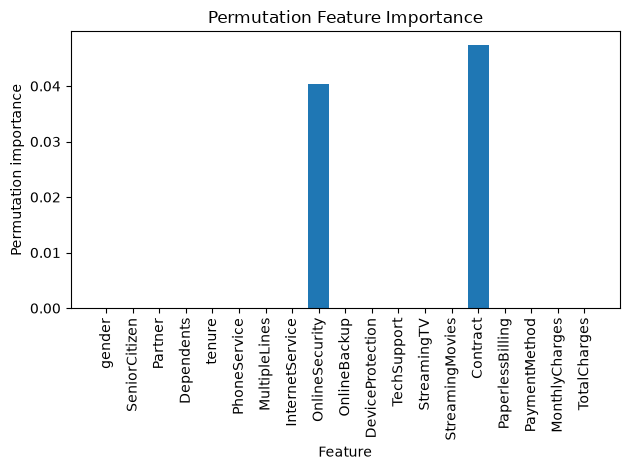

In [33]:
plt.bar(feature_names, importances)

plt.xlabel("Feature")
plt.ylabel("Permutation importance")
plt.title("Permutation Feature Importance")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()